# ADHD-200 phenotypic data — EDA **before** and **after** cleaning

Companion notebook for the manuscript *“Explainable Machine Learning for Multiclass ADHD Classification from Phenotypic Data”*.

**Inputs** (same folder as this notebook)

| File | Role |
|---|---|
| `adhd200_preprocessed_phenotypics.tsv` | raw phenotypic file (973 participants) |
| `adhd_cleaned_multiclass.csv` | output of `cleaning_multiclass.ipynb` (505 participants) |

**Outputs** — `eda_figures/*.png` (300 dpi) and `eda_tables/*.csv`.

| Part | Content | Manuscript section |
|---|---|---|
| A | Raw data: missing tokens, missingness by site, label availability, handedness coding, raw ranges | Data cleaning · Dataset and class distribution |
| B | The cleaning pipeline re-run step by step (participant flow, effect of the dropped columns) | Data cleaning · Missing data and predictor variables |
| C | Cleaned data: Table 1, Fig. 1, class-wise descriptives, distributions, correlations, site composition | Results · Dataset and class distribution |
| D | Before vs after: who was lost in the complete-case step? | Results / Limitations |
| E | Check of every number quoted in the manuscript against the data | – |

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from IPython.display import display
warnings.filterwarnings('ignore')

RAW_FILE   = 'adhd200_preprocessed_phenotypics.tsv'
CLEAN_FILE = 'adhd_cleaned_multiclass.csv'
FIG_DIR, TAB_DIR = 'eda_figures', 'eda_tables'
SEED = 42
for d in (FIG_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)

sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False})

CLASS_NAMES = {0: 'Control', 1: 'ADHD-Combined', 2: 'ADHD-Inattentive'}
CLASS_ORDER = list(CLASS_NAMES.values())
PALETTE     = dict(zip(CLASS_ORDER, ['#4C72B0', '#DD8452', '#55A868']))
RAW_DX_NAMES = {0: 'Control', 1: 'ADHD-Combined', 2: 'ADHD-Hyper/Impulsive', 3: 'ADHD-Inattentive'}
SITE_NAMES  = {1: 'Peking', 2: 'Brown', 3: 'KKI', 4: 'NeuroIMAGE', 5: 'NYU', 6: 'OHSU', 7: 'Pittsburgh', 8: 'WashU'}
GENDER_NAMES = {0: 'Female', 1: 'Male'}          # ADHD-200 coding; edit if your labels differ

FEATURES = ['Gender', 'Age', 'Handedness', 'ADHD_Measure', 'ADHD_Index', 'Inattentive',
            'Hyper_Impulsive', 'IQ_Measure', 'Verbal_IQ', 'Performance_IQ', 'Full4_IQ']
CAT = ['Gender', 'Handedness', 'ADHD_Measure', 'IQ_Measure']
NUM = [c for c in FEATURES if c not in CAT]
DROPPED = ['ScanDir_ID', 'Site', 'QC_Athena', 'QC_NIAK', 'Full2_IQ', 'Secondary_Dx', 'Med_Status']

def save_fig(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.png'); plt.show()

def save_tab(df, name, index=True):
    df.to_csv(f'{TAB_DIR}/{name}.csv', index=index); return df

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def fmt_p(p):
    return '<0.001' if p < 0.001 else f'{p:.3f}'

# Part A — Raw data (before cleaning)

## A1. Load as text and count the “missing” tokens

Everything is read as text so nothing is changed silently by type inference. `pending`, `N/A` and `-999` all mean *missing* in ADHD-200. The table counts each token **before** they are converted to `NaN`.

In [2]:
raw = pd.read_csv(RAW_FILE, sep='\t', dtype=str)
raw.columns = raw.columns.str.strip().str.replace(r'[ /]', '_', regex=True)     # 'Hyper/Impulsive' -> 'Hyper_Impulsive'
raw = raw.apply(lambda s: s.str.strip())
print('raw shape:', raw.shape)

TOKENS = {'pending': r'(?i)^pending$', 'N/A': r'(?i)^n/?a$', '-999': r'^-999(\.0+)?$'}
tok = pd.DataFrame({k: raw.apply(lambda s: s.str.match(rx).sum()) for k, rx in TOKENS.items()})
tok['blank'] = raw.isna().sum()
tok['total_missing'] = tok.sum(axis=1)
tok['percent'] = (tok['total_missing'] / len(raw) * 100).round(1)
save_tab(tok, 'A1_missing_tokens_raw')
display(raw.head())
tok

raw shape: (973, 19)


,ScanDir_ID,Site,Gender,Age,Handedness,DX,Secondary_Dx,ADHD_Measure,ADHD_Index,Inattentive,Hyper_Impulsive,IQ_Measure,Verbal_IQ,Performance_IQ,Full2_IQ,Full4_IQ,Med_Status,QC_Athena,QC_NIAK
0,2371032,3,0,10.73,1,0,NaN,2,47,55,43,1,121,119,NaN,122,1,1,1
1,2026113,3,0,12.99,1,1,NaN,2,90,89,78,1,122,108,NaN,106,1,1,1
2,3434578,3,0,8.12,1,0,NaN,2,42,42,43,1,85,98,NaN,89,1,1,1
3,8628223,3,0,10.81,1,0,Simple phobia,2,42,49,49,1,85,86,NaN,97,1,1,1
4,1623716,3,0,12.65,1,1,NaN,2,87,90,90,1,89,88,NaN,89,1,1,1


,pending,N/A,-999,blank,total_missing,percent
ScanDir_ID,0,0,0,0,0,0.0
Site,0,0,0,0,0,0.0
Gender,0,0,0,1,1,0.1
Age,0,0,0,0,0,0.0
Handedness,0,0,6,3,9,0.9
DX,26,0,0,0,26,2.7
Secondary_Dx,26,0,0,816,842,86.5
ADHD_Measure,26,0,0,318,344,35.4
ADHD_Index,26,0,30,360,416,42.8
Inattentive,26,0,30,281,337,34.6


## A2. Convert tokens to `NaN` and fix types

Same operations as `cleaning_multiclass.ipynb`: all tokens → `NaN`; the single `L` in Handedness → `0`; every column except `Secondary_Dx` → numeric.

In [3]:
MISSING_TOKENS = r'(?i)^(pending|n/?a|nan|-999(\.0+)?)$'
na = raw.replace(MISSING_TOKENS, np.nan, regex=True)

n_L = int((na['Handedness'].str.upper() == 'L').sum())
print("Participants with handedness stored as the letter 'L':", n_L)

typed = na.copy()
typed['Handedness'] = typed['Handedness'].str.upper().replace({'L': '0', 'R': '1'})
NUM_COLS_RAW = [c for c in typed.columns if c != 'Secondary_Dx']
typed[NUM_COLS_RAW] = typed[NUM_COLS_RAW].apply(pd.to_numeric, errors='coerce')
typed['SiteName'] = typed['Site'].map(SITE_NAMES)
print(typed.dtypes.to_string())

Participants with handedness stored as the letter 'L': 1
ScanDir_ID           int64
Site                 int64
Gender             float64
Age                float64
Handedness         float64
DX                 float64
Secondary_Dx        object
ADHD_Measure       float64
ADHD_Index         float64
Inattentive        float64
Hyper_Impulsive    float64
IQ_Measure         float64
Verbal_IQ          float64
Performance_IQ     float64
Full2_IQ           float64
Full4_IQ           float64
Med_Status         float64
QC_Athena          float64
QC_NIAK            float64
SiteName            object


## A3. Sites, label availability and class sizes (raw)

`DX = pending` marks the held-out ADHD-200 test labels (all of Brown/Bradley). The raw four-class coding is 0 Control, 1 ADHD-Combined, 2 ADHD-Hyperactive/Impulsive, 3 ADHD-Inattentive.

DX_label,Control,ADHD-Combined,ADHD-Hyper/Impulsive,ADHD-Inattentive,Unlabelled (pending),Total
SiteName,,,,,,
Peking,143,38,1,63,0,245
Brown,0,0,0,0,26,26
KKI,69,19,1,5,0,94
NeuroIMAGE,37,29,6,1,0,73
NYU,111,99,2,51,0,263
OHSU,70,27,3,13,0,113
Pittsburgh,94,0,0,4,0,98
WashU,61,0,0,0,0,61
All sites,585,212,13,137,26,973


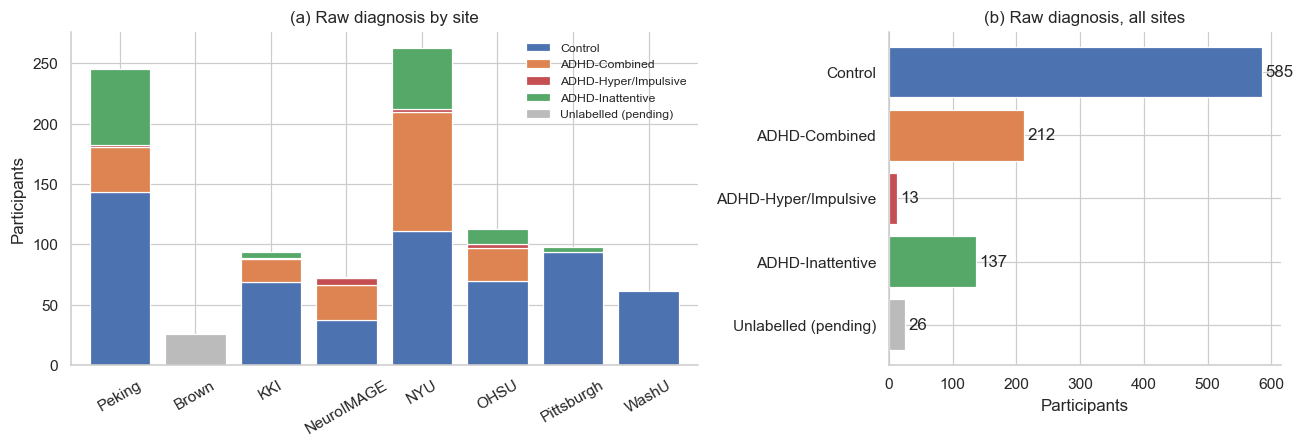

In [4]:
typed['DX_label'] = typed['DX'].map(RAW_DX_NAMES).fillna('Unlabelled (pending)')
dx_order = ['Control', 'ADHD-Combined', 'ADHD-Hyper/Impulsive', 'ADHD-Inattentive', 'Unlabelled (pending)']
site_dx = (pd.crosstab(typed['SiteName'], typed['DX_label'])
             .reindex(index=[SITE_NAMES[i] for i in range(1, 9)], columns=dx_order, fill_value=0))
site_dx['Total'] = site_dx.sum(axis=1)
site_dx.loc['All sites'] = site_dx.sum()
save_tab(site_dx, 'A3_site_by_dx_raw')
display(site_dx)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.6, 1]})
cols = ['#4C72B0', '#DD8452', '#C44E52', '#55A868', '#BBBBBB']
site_dx.drop(index='All sites').drop(columns='Total')[dx_order].plot(kind='bar', stacked=True, ax=axes[0], color=cols, width=.8)
axes[0].set_xlabel(''); axes[0].set_ylabel('Participants'); axes[0].set_title('(a) Raw diagnosis by site')
axes[0].tick_params(axis='x', rotation=30); axes[0].legend(title='', fontsize=8, frameon=False)

tot = site_dx.loc['All sites', dx_order]
axes[1].barh(dx_order[::-1], tot.values[::-1], color=cols[::-1])
for i, v in enumerate(tot.values[::-1]): axes[1].text(v + 5, i, str(int(v)), va='center')
axes[1].set_title('(b) Raw diagnosis, all sites'); axes[1].set_xlabel('Participants')
plt.tight_layout(); save_fig(fig, 'A3_raw_dx_by_site')

## A4. Missing values in the raw file

Two views: how much of each column is missing, and **where** it is missing. If the heat-map shows whole columns empty for whole sites, missingness is *structured by site* and not random, which is the argument for complete-case analysis instead of imputation. Percentages in panel (a) are given for all 973 rows and for the 947 labelled rows.

,missing_n_all973,missing_pct_all973,missing_pct_labelled947,role
Full2_IQ,902,92.7,92.5,dropped
Secondary_Dx,842,86.5,86.2,dropped
ADHD_Index,416,42.8,41.2,predictor
Med_Status,409,42.0,40.4,dropped
ADHD_Measure,344,35.4,33.6,predictor
Hyper_Impulsive,337,34.6,32.8,predictor
Inattentive,337,34.6,32.8,predictor
Verbal_IQ,301,30.9,31.8,predictor
Performance_IQ,301,30.9,31.8,predictor
Full4_IQ,86,8.8,9.1,predictor


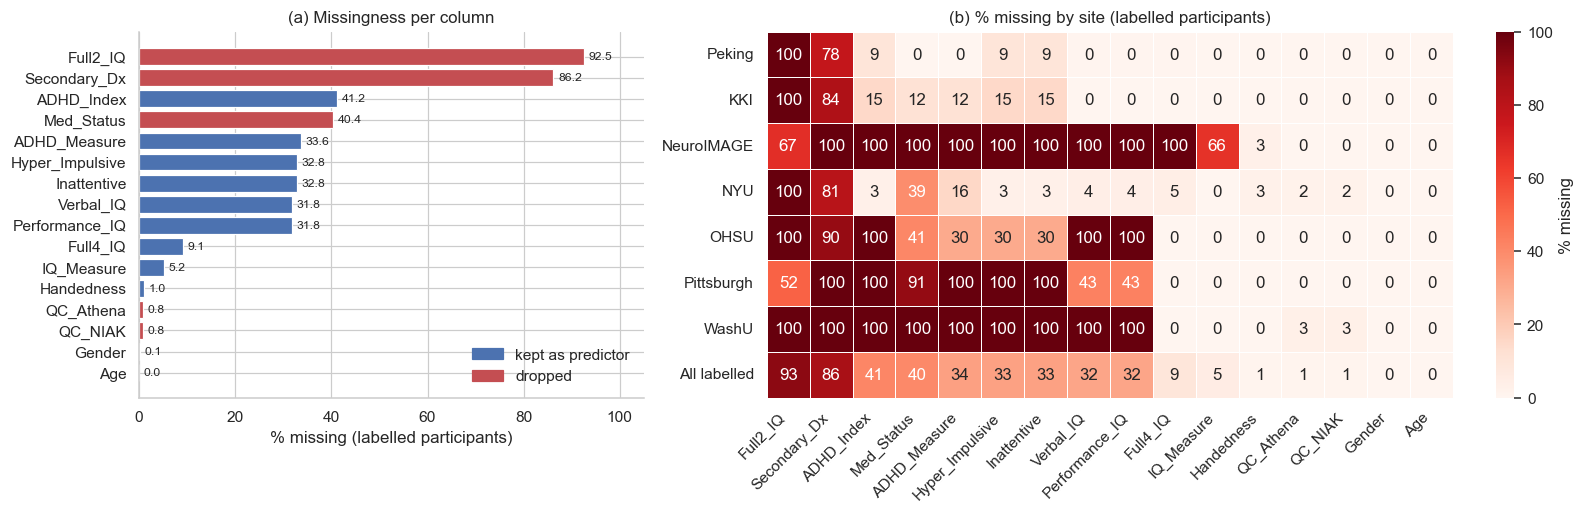

In [5]:
lab_mask_raw = typed['DX'].notna()
miss = pd.DataFrame({
    'missing_n_all973': typed.isna().sum(),
    'missing_pct_all973': (typed.isna().mean() * 100).round(1),
    'missing_pct_labelled947': (typed[lab_mask_raw].isna().mean() * 100).round(1),
}).drop(index=['SiteName', 'DX_label', 'ScanDir_ID', 'Site'])
miss['role'] = np.where(miss.index.isin(DROPPED), 'dropped',
                np.where(miss.index.isin(FEATURES), 'predictor', 'target'))
miss = miss.sort_values('missing_pct_labelled947', ascending=False)
save_tab(miss, 'A4_missing_by_column_raw')
display(miss)

# site x column heat-map (labelled participants only, so the 26 unlabelled rows do not mask the pattern)
cols_hm = [c for c in miss.index if c != 'DX']
sub = typed[lab_mask_raw]
hm = sub[cols_hm].isna().groupby(sub['SiteName']).mean().mul(100)
hm = hm.reindex([SITE_NAMES[i] for i in range(1, 9) if i != 2])           # Brown has no labelled rows
hm.loc['All labelled'] = sub[cols_hm].isna().mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1, 1.7]})
colmap = {'dropped': '#C44E52', 'predictor': '#4C72B0'}
m = miss.drop(index='DX')
axes[0].barh(m.index[::-1], m['missing_pct_labelled947'][::-1], color=[colmap[r] for r in m['role'][::-1]])
for i, v in enumerate(m['missing_pct_labelled947'][::-1]): axes[0].text(v + 1, i, f'{v:.1f}', va='center', fontsize=8)
axes[0].set_xlim(0, 105); axes[0].set_xlabel('% missing (labelled participants)'); axes[0].set_title('(a) Missingness per column')
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=colmap['predictor'], label='kept as predictor'), Patch(color=colmap['dropped'], label='dropped')],
               frameon=False, loc='lower right')
sns.heatmap(hm[m.index], annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, linewidths=.5,
            cbar_kws={'label': '% missing'}, ax=axes[1])
axes[1].set_title('(b) % missing by site (labelled participants)'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')
plt.tight_layout(); save_fig(fig, 'A4_missingness_raw')

## A5. Handedness was recorded in two different ways

Most sites use a categorical code (0 = left, 1 = right, 2 = ambidextrous); **NYU** stores a continuous Edinburgh Handedness Inventory score in [−1, 1]; one NeuroIMAGE participant has the code 3 (a documented recoding error for 2). The figure makes it clear why a direct merge would be wrong.

Handedness,0,1,2,3,L
SiteName,,,,,
Peking,3,241,0,0,1
KKI,9,84,1,0,0
NeuroIMAGE,8,62,0,1,0
OHSU,0,113,0,0,0
Pittsburgh,4,94,0,0,0
WashU,0,61,0,0,0


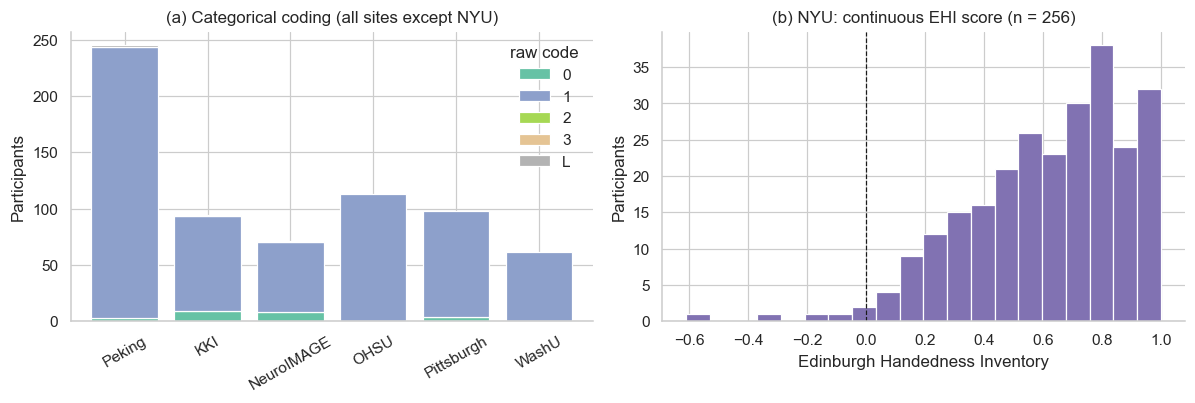

In [6]:
h = na[['Site', 'Handedness']].copy()
h['Site'] = pd.to_numeric(h['Site']); h['Handedness'] = h['Handedness'].str.upper()
nyu_vals = pd.to_numeric(h.loc[h['Site'] == 5, 'Handedness'], errors='coerce').dropna()
other = h.loc[(h['Site'] != 5) & h['Handedness'].notna()].copy()
other['SiteName'] = other['Site'].map(SITE_NAMES)
hc = pd.crosstab(other['SiteName'], other['Handedness'])
hc = hc.reindex([SITE_NAMES[i] for i in [1, 3, 4, 6, 7, 8]])
save_tab(hc, 'A5_handedness_codes_non_nyu')
display(hc)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hc.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2', width=.8)
axes[0].set_title('(a) Categorical coding (all sites except NYU)'); axes[0].set_xlabel(''); axes[0].set_ylabel('Participants')
axes[0].tick_params(axis='x', rotation=30); axes[0].legend(title='raw code', frameon=False)
axes[1].hist(nyu_vals, bins=20, color='#8172B2', edgecolor='white')
axes[1].axvline(0, color='k', lw=.8, ls='--')
axes[1].set_title(f'(b) NYU: continuous EHI score (n = {len(nyu_vals)})'); axes[1].set_xlabel('Edinburgh Handedness Inventory'); axes[1].set_ylabel('Participants')
plt.tight_layout(); save_fig(fig, 'A5_handedness_raw_coding')

## A6. Raw ranges of the numeric columns

A quick sanity check after `−999` has been turned into `NaN`: implausible minima/maxima would show up here.

In [7]:
num_raw = typed[[c for c in NUM_COLS_RAW if c not in ['ScanDir_ID', 'Site']]]
rng = num_raw.agg(['count', 'mean', 'std', 'min', 'median', 'max']).T.round(2)
save_tab(rng, 'A6_raw_numeric_summary')
rng

,count,mean,std,min,median,max
Gender,972.0,0.62,0.49,0.00,1.00,1.00
Age,973.0,12.03,3.33,7.09,11.42,26.31
Handedness,964.0,0.87,0.28,-0.61,1.00,3.00
DX,947.0,0.69,1.05,0.00,0.00,3.00
ADHD_Measure,629.0,1.74,0.67,1.00,2.00,3.00
ADHD_Index,557.0,50.66,17.45,18.00,47.00,99.00
Inattentive,636.0,45.61,22.16,9.00,44.00,90.00
Hyper_Impulsive,636.0,43.71,23.01,9.00,44.00,90.00
IQ_Measure,898.0,2.39,0.87,1.00,2.00,5.00
Verbal_IQ,672.0,112.49,14.46,65.00,112.00,158.00


# Part B — The cleaning pipeline, step by step

This part repeats the logic of `cleaning_multiclass.ipynb` while **keeping `Site` and the dropped columns alive**, so that we can (i) draw the participant flow, (ii) measure what each decision costs, and (iii) later describe the site composition of the final data. At the end the result is compared row by row with `adhd_cleaned_multiclass.csv`.

## B1. Handedness harmonisation

In [8]:
d = typed.copy()
site, hand = d['Site'], d['Handedness']
is_nyu    = site.eq(5)
cat_ok    = ~is_nyu & hand.isin([0, 1, 2])
fix_site4 = site.eq(4) & hand.eq(3)
ehi_ok    = is_nyu & hand.between(-1, 1)

hand_std = pd.Series(np.nan, index=d.index, dtype=float)
hand_std.loc[cat_ok]    = hand.loc[cat_ok]
hand_std.loc[fix_site4] = 2
hand_std.loc[ehi_ok]    = np.select([hand[ehi_ok] < 0, hand[ehi_ok] > 0], [0, 1], default=2)

print(f'categorical codes kept as is       : {int(cat_ok.sum())}')
print(f'NYU EHI scores converted to 0/1/2  : {int(ehi_ok.sum())}')
print(f'NeuroIMAGE 3 -> 2 recoding fixes   : {int(fix_site4.sum())}')
print(f"letter 'L' -> 0 (done in A2)       : {n_L}")
print(f'values that matched no rule        : {int((hand.notna() & hand_std.isna()).sum())}')
d['Handedness'] = hand_std

hb = pd.crosstab(d['SiteName'], d['Handedness'].fillna(-1)).rename(columns={-1.0: 'missing', 0.0: 'left (0)', 1.0: 'right (1)', 2.0: 'ambidextrous (2)'})
hb = hb.reindex([SITE_NAMES[i] for i in range(1, 9)])
save_tab(hb, 'B1_handedness_after_harmonisation')
hb

categorical codes kept as is       : 707
NYU EHI scores converted to 0/1/2  : 256
NeuroIMAGE 3 -> 2 recoding fixes   : 1
letter 'L' -> 0 (done in A2)       : 1
values that matched no rule        : 0


Handedness,missing,left (0),right (1),ambidextrous (2)
SiteName,,,,
Peking,0,4,241,0
Brown,0,1,25,0
KKI,0,9,84,1
NeuroIMAGE,2,8,62,1
NYU,7,5,250,1
OHSU,0,0,113,0
Pittsburgh,0,4,94,0
WashU,0,0,61,0


## B2. Outcome definition: unlabelled rows and the merge of Hyperactive/Impulsive into Combined

In [9]:
DX_MAP = {0: 0, 1: 1, 2: 1, 3: 2}                       # H/I (2) merged into Combined (1); Inattentive 3 -> 2
n_all = len(d)
lab = d.dropna(subset=['DX']).copy()
lab['DX_raw'] = lab['DX'].astype(int)
lab['DX'] = lab['DX_raw'].map(DX_MAP)

raw4 = lab['DX_raw'].map(RAW_DX_NAMES).value_counts().reindex(list(RAW_DX_NAMES.values()))
cls3 = lab['DX'].map(CLASS_NAMES).value_counts().reindex(CLASS_ORDER)
print(f'all rows: {n_all} | unlabelled (pending): {n_all - len(lab)} | labelled: {len(lab)}')
print('\nraw 4-class counts:\n', raw4.to_string())
print('\nmerged 3-class counts:\n', cls3.to_string())

all rows: 973 | unlabelled (pending): 26 | labelled: 947

raw 4-class counts:
 DX_raw
Control                 585
ADHD-Combined           212
ADHD-Hyper/Impulsive     13
ADHD-Inattentive        137

merged 3-class counts:
 DX
Control             585
ADHD-Combined       225
ADHD-Inattentive    137


## B3. What do the dropped columns cost?

`Med_Status` and `Full2_IQ` were dropped partly because of the *rows* they would remove in the complete-case step. The table re-runs the complete-case filter with each of them added back to the 11 predictors.

In [10]:
def n_complete(cols):
    sub = lab[cols + ['DX']].dropna()
    return pd.Series({'complete_cases': len(sub), **{CLASS_NAMES[k]: int((sub['DX'] == k).sum()) for k in (0, 1, 2)}})

scen = {
    '11 predictors (final set)':            FEATURES,
    '+ Med_Status':                         FEATURES + ['Med_Status'],
    '+ Full2_IQ':                           FEATURES + ['Full2_IQ'],
    '+ Med_Status + Full2_IQ':              FEATURES + ['Med_Status', 'Full2_IQ'],
}
abl = pd.DataFrame({k: n_complete(v) for k, v in scen.items()}).T
abl['lost_vs_947_%'] = ((1 - abl['complete_cases'] / len(lab)) * 100).round(1)
save_tab(abl, 'B3_complete_case_ablation')
display(abl)

# Is Med_Status missingness related to diagnosis and site? (supports "missingness depended on site and diagnosis")
ms = lab['Med_Status'].isna()
by_dx   = lab.assign(ms=ms).groupby(lab['DX'].map(CLASS_NAMES))['ms'].agg(['sum', 'mean', 'size'])
by_dx.columns = ['n_missing', 'prop_missing', 'n']; by_dx['prop_missing'] = (by_dx['prop_missing'] * 100).round(1)
by_site = lab.assign(ms=ms).groupby('SiteName')['ms'].agg(['sum', 'mean', 'size'])
by_site.columns = ['n_missing', 'prop_missing', 'n']; by_site['prop_missing'] = (by_site['prop_missing'] * 100).round(1)
chi_dx   = stats.chi2_contingency(pd.crosstab(lab['DX'], ms))
chi_site = stats.chi2_contingency(pd.crosstab(lab['Site'], ms))
print(f'Med_Status missing in {ms.mean()*100:.1f}% of labelled participants')
print(f'  vs diagnosis: chi2 = {chi_dx[0]:.1f}, p = {fmt_p(chi_dx[1])}')
print(f'  vs site     : chi2 = {chi_site[0]:.1f}, p = {fmt_p(chi_site[1])}')
display(by_dx); display(by_site)
save_tab(by_dx, 'B3_med_status_missing_by_dx'); save_tab(by_site, 'B3_med_status_missing_by_site')

,complete_cases,Control,ADHD-Combined,ADHD-Inattentive,lost_vs_947_%
11 predictors (final set),505,271,130,104,46.7
+ Med_Status,444,271,86,87,53.1
+ Full2_IQ,0,0,0,0,100.0
+ Med_Status + Full2_IQ,0,0,0,0,100.0


Med_Status missing in 40.4% of labelled participants
  vs diagnosis: chi2 = 35.3, p = <0.001
  vs site     : chi2 = 499.4, p = <0.001


,n_missing,prop_missing,n
DX,,,
ADHD-Combined,117,52.0,225
ADHD-Inattentive,28,20.4,137
Control,238,40.7,585


,n_missing,prop_missing,n
SiteName,,,
KKI,11,11.7,94
NYU,103,39.2,263
NeuroIMAGE,73,100.0,73
OHSU,46,40.7,113
Peking,0,0.0,245
Pittsburgh,89,90.8,98
WashU,61,100.0,61


,n_missing,prop_missing,n
SiteName,,,
KKI,11,11.7,94
NYU,103,39.2,263
NeuroIMAGE,73,100.0,73
OHSU,46,40.7,113
Peking,0,0.0,245
Pittsburgh,89,90.8,98
WashU,61,100.0,61


## B4. Complete-case filtering and check against the cleaned file

In [11]:
mask = lab[FEATURES + ['DX']].notna().all(axis=1)
fin = lab.loc[mask].copy()
site_fin = fin['Site'].astype(int).reset_index(drop=True)

clean = fin[FEATURES + ['DX']].reset_index(drop=True)
clean[CAT + ['DX']] = clean[CAT + ['DX']].astype(int)

ref = pd.read_csv(CLEAN_FILE)
pd.testing.assert_frame_equal(clean, ref, check_dtype=False)
print('✓ re-computed cleaned data == adhd_cleaned_multiclass.csv  (shape', ref.shape, ')')
df = ref.copy()
df['Class'] = pd.Categorical(df['DX'].map(CLASS_NAMES), categories=CLASS_ORDER, ordered=True)
df['Site'] = site_fin.map(SITE_NAMES).values

✓ re-computed cleaned data == adhd_cleaned_multiclass.csv  (shape (505, 12) )


## B5. Participant flow

,Step,n,% of 947 labelled
0,Rows in raw phenotypic file,973,102.7
1,− DX = pending (no public label),-26,2.7
2,= Labelled participants,947,100.0
3,− any missing value in the 11 predictors,-442,46.7
4,= Final analysis set,505,53.3


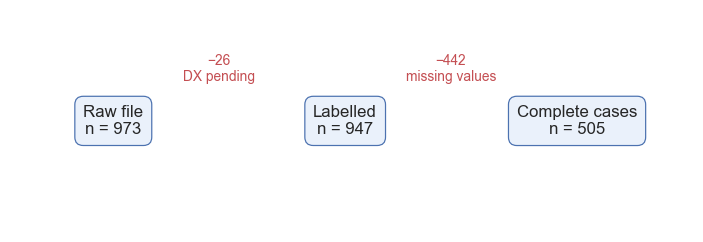

In [12]:
flow = pd.DataFrame([
    ('Rows in raw phenotypic file',                      n_all,        np.nan),
    ('− DX = pending (no public label)',                 -(n_all - len(lab)), np.nan),
    ('= Labelled participants',                          len(lab),     np.nan),
    ('− any missing value in the 11 predictors',         -(len(lab) - len(fin)), np.nan),
    ('= Final analysis set',                             len(fin),     np.nan),
], columns=['Step', 'n', '_'])[['Step', 'n']]
flow['% of 947 labelled'] = (flow['n'].abs() / len(lab) * 100).round(1)
save_tab(flow, 'B5_participant_flow', index=False)
display(flow)

fig, ax = plt.subplots(figsize=(8, 2.6))
boxes = [(f'Raw file\nn = {n_all}', .02), (f'Labelled\nn = {len(lab)}', .36), (f'Complete cases\nn = {len(fin)}', .70)]
for txt, x in boxes:
    ax.text(x + .13, .5, txt, ha='center', va='center', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.5', fc='#EAF1FB', ec='#4C72B0'))
ax.annotate('', xy=(.34, .5), xytext=(.27, .5), arrowprops=dict(arrowstyle='->'))
ax.annotate('', xy=(.68, .5), xytext=(.61, .5), arrowprops=dict(arrowstyle='->'))
ax.text(.305, .68, f'−{n_all - len(lab)}\nDX pending', ha='center', fontsize=9, color='#C44E52')
ax.text(.645, .68, f'−{len(lab) - len(fin)}\nmissing values', ha='center', fontsize=9, color='#C44E52')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
save_fig(fig, 'B5_participant_flow')

# Part C — Cleaned data (after cleaning)

Everything below uses `adhd_cleaned_multiclass.csv` (n = 505), i.e. exactly the data that enter the modelling notebook.

## C1. Table 1 — class distribution at each stage

In [13]:
X, y = df[FEATURES], df['DX']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

def row(label, series):
    c = series.value_counts().reindex([0, 1, 2], fill_value=0)
    return {'Stage': label, 'Control': c[0], 'ADHD-combined': c[1], 'ADHD-inattentive': c[2], 'Total': int(c.sum())}

table1 = pd.DataFrame([
    row('Labelled participants (H/I merged into combined)', lab['DX']),
    row('After complete-case filtering (full dataset)', y),
    row('Training set (75%)', y_tr),
    row('Test set (25%)', y_te),
])
save_tab(table1, 'C1_table1_class_distribution', index=False)
table1

,Stage,Control,ADHD-combined,ADHD-inattentive,Total
0,Labelled participants (H/I merged into combined),585,225,137,947
1,After complete-case filtering (full dataset),271,130,104,505
2,Training set (75%),203,97,78,378
3,Test set (25%),68,33,26,127


## C2. Fig. 1 — class distribution (final data) and how the classes evolved

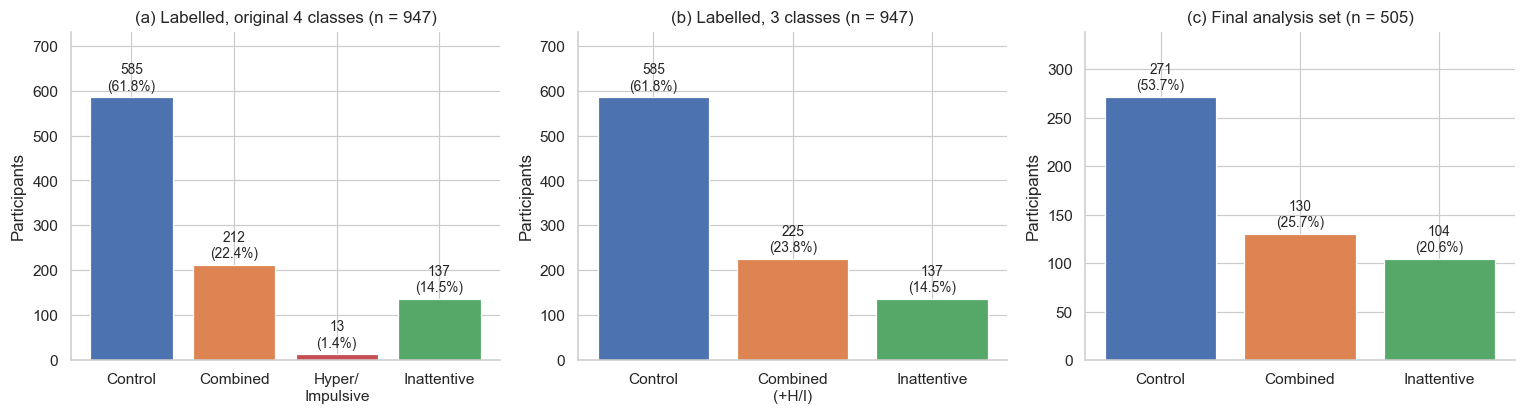

Imbalance: 2.61 controls per ADHD-inattentive participant; 2.08 per ADHD-combined


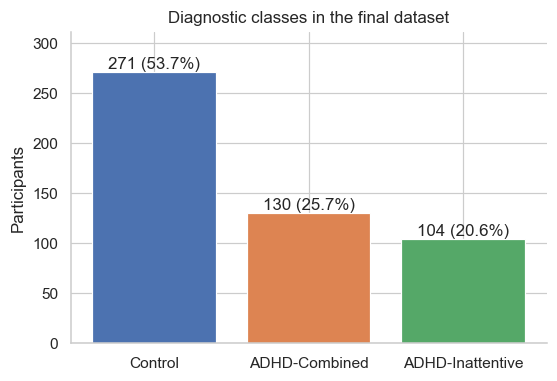

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=False)

# (a) raw 4 classes, labelled
c4 = lab['DX_raw'].map(RAW_DX_NAMES).value_counts().reindex(list(RAW_DX_NAMES.values()))
b = axes[0].bar(range(4), c4.values, color=['#4C72B0', '#DD8452', '#C44E52', '#55A868'])
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(['Control', 'Combined', 'Hyper/\nImpulsive', 'Inattentive'])
axes[0].set_title(f'(a) Labelled, original 4 classes (n = {len(lab)})')
# (b) merged 3 classes, labelled
c3 = lab['DX'].map(CLASS_NAMES).value_counts().reindex(CLASS_ORDER)
axes[1].bar(range(3), c3.values, color=[PALETTE[c] for c in CLASS_ORDER])
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(['Control', 'Combined\n(+H/I)', 'Inattentive'])
axes[1].set_title(f'(b) Labelled, 3 classes (n = {len(lab)})')
# (c) final
cf = df['Class'].value_counts().reindex(CLASS_ORDER)
axes[2].bar(range(3), cf.values, color=[PALETTE[c] for c in CLASS_ORDER])
axes[2].set_xticks(range(3)); axes[2].set_xticklabels(['Control', 'Combined', 'Inattentive'])
axes[2].set_title(f'(c) Final analysis set (n = {len(df)})')
for ax, vals in zip(axes, [c4, c3, cf]):
    tot = vals.sum()
    for i, v in enumerate(vals.values):
        ax.text(i, v + tot * .01, f'{v}\n({v / tot * 100:.1f}%)', ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, vals.max() * 1.25); ax.set_ylabel('Participants')
plt.tight_layout(); save_fig(fig, 'C2_class_distribution')

# the stand-alone Fig. 1 of the manuscript (final data only)
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.bar(CLASS_ORDER, cf.values, color=[PALETTE[c] for c in CLASS_ORDER])
for i, v in enumerate(cf.values): ax.text(i, v + 4, f'{v} ({v / len(df) * 100:.1f}%)', ha='center')
ax.set_ylim(0, cf.max() * 1.15); ax.set_ylabel('Participants'); ax.set_title('Diagnostic classes in the final dataset')
print(f'Imbalance: {cf.iloc[0] / cf.iloc[2]:.2f} controls per ADHD-inattentive participant; {cf.iloc[0] / cf.iloc[1]:.2f} per ADHD-combined')
plt.tight_layout(); save_fig(fig, 'Fig1_class_distribution_final')

## C3. Descriptive table by class

Numeric variables: mean (SD), compared across the three classes with the Kruskal–Wallis test (effect size ε²). Categorical variables: n (%), compared with the χ² test (effect size Cramér’s V). *p* values are Holm-adjusted over all 11 predictors. These tests are descriptive; they are **not** used for feature selection.

In [15]:
rows, pvals = [], []
for c in NUM:
    groups = [df.loc[df['DX'] == k, c] for k in (0, 1, 2)]
    H, p = stats.kruskal(*groups); n = len(df)
    eps2 = max(0.0, (H - 3 + 1) / (n - 3))
    r = {'Variable': f'{c}, mean (SD)'}
    for k, g in zip(CLASS_ORDER, groups): r[k] = f'{g.mean():.1f} ({g.std():.1f})'
    r['Overall'] = f'{df[c].mean():.1f} ({df[c].std():.1f})'
    r['Test'] = 'Kruskal-Wallis'; r['Effect size'] = f'ε² = {eps2:.3f}'; r['p_raw'] = p
    rows.append(r); pvals.append(p)

cat_labels = {'Gender': GENDER_NAMES, 'Handedness': {0: 'Left', 1: 'Right', 2: 'Ambidextrous'}}
for c in CAT:
    ct = pd.crosstab(df['DX'], df[c]); chi2, p, dof, exp = stats.chi2_contingency(ct)
    V = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
    levels = sorted(df[c].unique())
    for j, lv in enumerate(levels):
        r = {'Variable': f'{c} = {cat_labels.get(c, {}).get(lv, lv)}, n (%)'}
        for k, name in CLASS_NAMES.items():
            n_k = int(((df['DX'] == k) & (df[c] == lv)).sum()); r[name] = f'{n_k} ({n_k / (df["DX"] == k).sum() * 100:.1f})'
        n_o = int((df[c] == lv).sum()); r['Overall'] = f'{n_o} ({n_o / len(df) * 100:.1f})'
        if j == 0:
            r['Test'] = 'Chi-square'; r['Effect size'] = f'V = {V:.3f}'; r['p_raw'] = p
            r['note'] = 'expected count < 5 in some cells' if (exp < 5).any() else ''
            pvals.append(p)
        rows.append(r)

desc = pd.DataFrame(rows)
tests_idx = desc.index[desc['p_raw'].notna()]
desc.loc[tests_idx, 'p_holm'] = [fmt_p(v) for v in holm(desc.loc[tests_idx, 'p_raw'])]
desc['p_raw'] = desc['p_raw'].map(lambda v: '' if pd.isna(v) else fmt_p(v))
desc = desc.fillna('')
header = pd.DataFrame([{'Variable': 'n', **{k: str(int((df["DX"] == i).sum())) for i, k in CLASS_NAMES.items()}, 'Overall': str(len(df))}])
desc = pd.concat([header, desc], ignore_index=True).fillna('')
save_tab(desc, 'C3_descriptives_by_class', index=False)
desc

,Variable,Control,ADHD-Combined,ADHD-Inattentive,Overall,Test,Effect size,p_raw,note,p_holm
0,n,271,130,104,505,,,,,
1,"Age, mean (SD)",11.3 (2.3),10.9 (2.3),12.1 (2.4),11.4 (2.3),Kruskal-Wallis,ε² = 0.030,<0.001,,<0.001
2,"ADHD_Index, mean (SD)",37.9 (9.9),66.9 (11.2),58.0 (14.7),49.5 (17.2),Kruskal-Wallis,ε² = 0.573,<0.001,,<0.001
3,"Inattentive, mean (SD)",31.7 (15.7),58.5 (20.6),46.9 (23.1),41.8 (21.9),Kruskal-Wallis,ε² = 0.251,<0.001,,<0.001
4,"Hyper_Impulsive, mean (SD)",31.2 (17.1),59.5 (22.8),38.5 (22.4),40.0 (23.1),Kruskal-Wallis,ε² = 0.257,<0.001,,<0.001
5,"Verbal_IQ, mean (SD)",116.1 (14.0),109.9 (15.9),107.2 (14.6),112.7 (15.1),Kruskal-Wallis,ε² = 0.064,<0.001,,<0.001
6,"Performance_IQ, mean (SD)",109.3 (14.1),102.8 (14.3),101.0 (14.0),105.9 (14.6),Kruskal-Wallis,ε² = 0.064,<0.001,,<0.001
7,"Full4_IQ, mean (SD)",114.1 (13.5),106.9 (14.2),104.6 (13.1),110.3 (14.2),Kruskal-Wallis,ε² = 0.084,<0.001,,<0.001
8,"Gender = Female, n (%)",124 (45.8),21 (16.2),25 (24.0),170 (33.7),Chi-square,V = 0.281,<0.001,,<0.001
9,"Gender = Male, n (%)",147 (54.2),109 (83.8),79 (76.0),335 (66.3),,,,,nan


## C4. Distributions of the numeric predictors by class

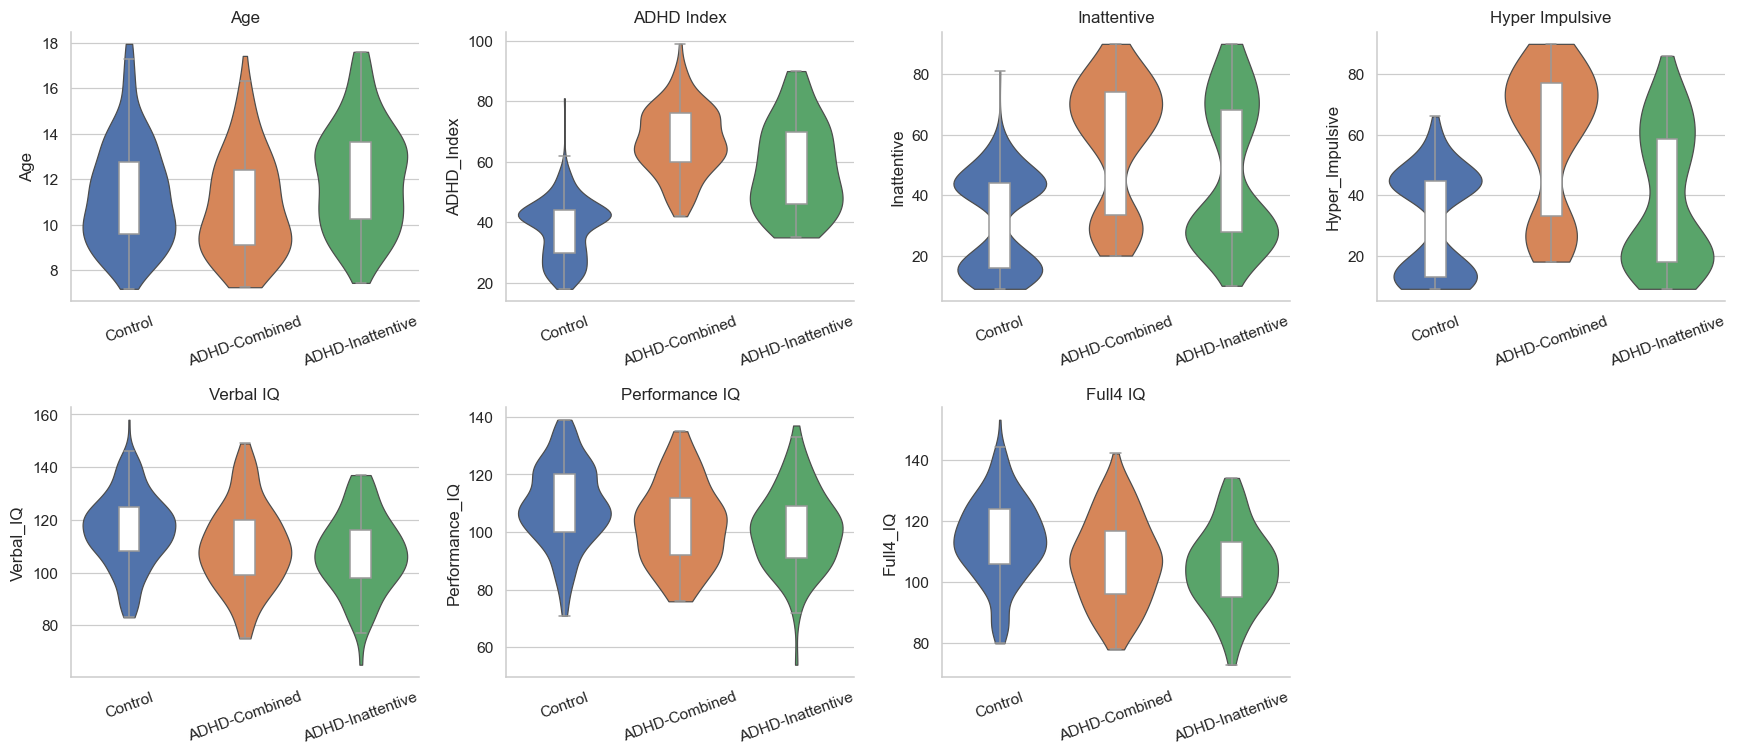

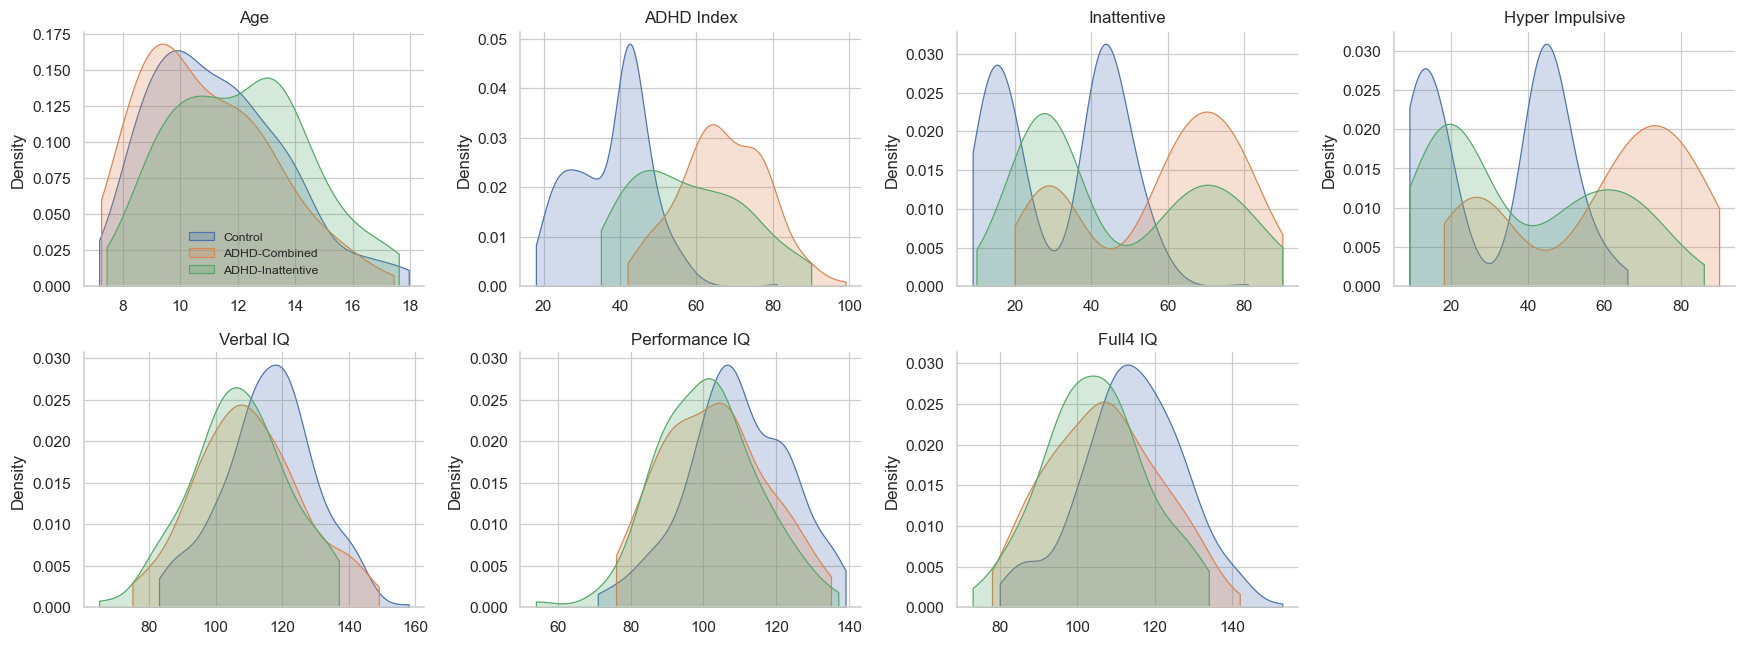

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, NUM):
    sns.violinplot(data=df, x='Class', y=c, hue='Class', palette=PALETTE, inner=None, cut=0, linewidth=.8, saturation=.9, legend=False, ax=ax)
    sns.boxplot(data=df, x='Class', y=c, width=.18, showfliers=False, boxprops=dict(facecolor='white', zorder=3), ax=ax, color='white')
    ax.set_xlabel(''); ax.set_title(c.replace('_', ' ')); ax.tick_params(axis='x', rotation=20)
axes.flat[-1].axis('off')
plt.tight_layout(); save_fig(fig, 'C4_numeric_by_class')

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.flat, NUM):
    for k in CLASS_ORDER:
        sns.kdeplot(df.loc[df['Class'] == k, c], ax=ax, color=PALETTE[k], fill=True, alpha=.25, label=k, cut=0, common_norm=False)
    ax.set_title(c.replace('_', ' ')); ax.set_xlabel(''); ax.set_ylabel('Density')
axes.flat[0].legend(frameon=False, fontsize=8); axes.flat[-1].axis('off')
plt.tight_layout(); save_fig(fig, 'C4_numeric_density_by_class')

## C5. Distributions of the coded (categorical) predictors by class

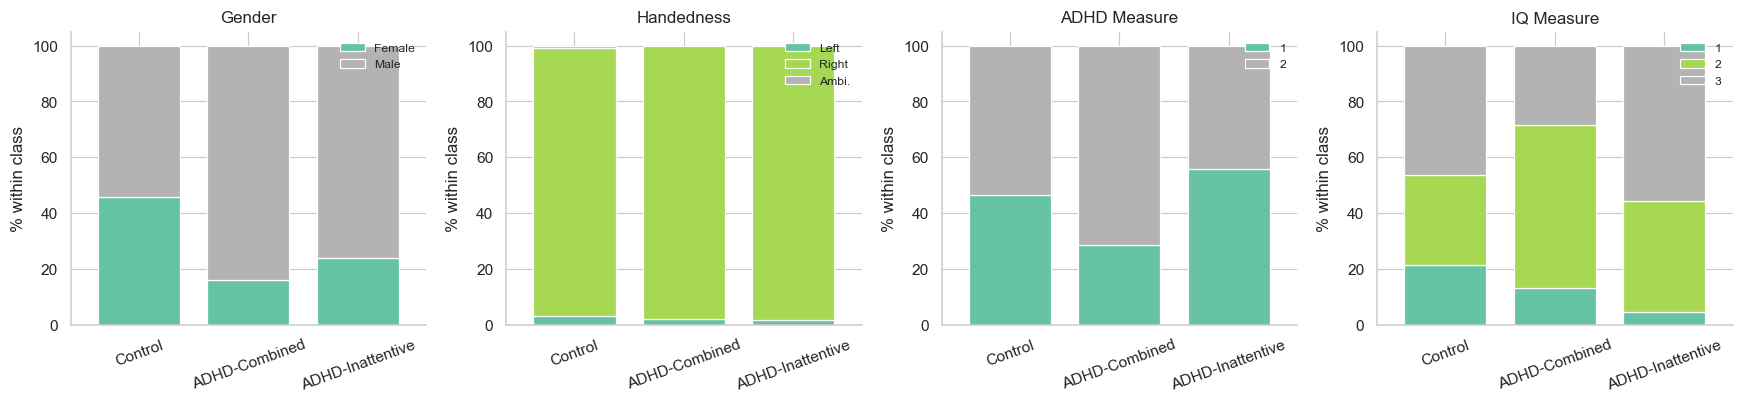

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes, CAT):
    p = pd.crosstab(df['Class'], df[c], normalize='index') * 100
    if c == 'Gender': p = p.rename(columns=GENDER_NAMES)
    if c == 'Handedness': p = p.rename(columns={0: 'Left', 1: 'Right', 2: 'Ambi.'})
    p.plot(kind='bar', stacked=True, ax=ax, colormap='Set2', width=.75)
    ax.set_title(c.replace('_', ' ')); ax.set_xlabel(''); ax.set_ylabel('% within class'); ax.tick_params(axis='x', rotation=20)
    ax.legend(title='', frameon=False, fontsize=8)
plt.tight_layout(); save_fig(fig, 'C5_categorical_by_class')

## C6. Correlations between predictors (Spearman)

Strong correlations (e.g. among the three IQ scores, or among the rating scales) are relevant for the coefficient and SHAP interpretation in the Results.

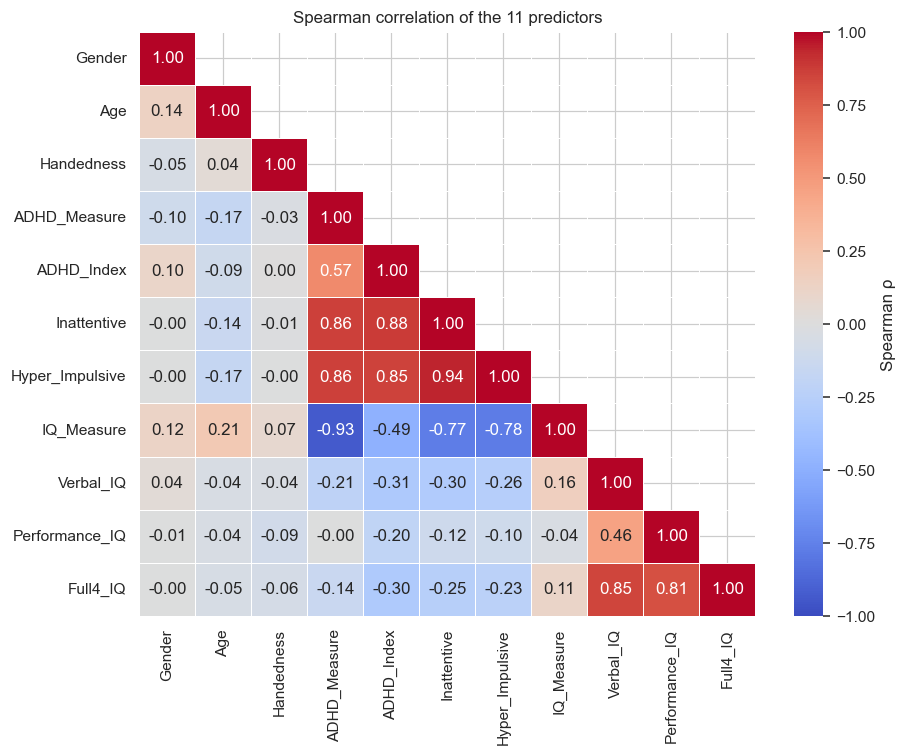

,var1,var2,rho
20,Hyper_Impulsive,Inattentive,0.941
24,IQ_Measure,ADHD_Measure,-0.934
14,Inattentive,ADHD_Index,0.878
18,Hyper_Impulsive,ADHD_Measure,0.860
13,Inattentive,ADHD_Measure,0.859
19,Hyper_Impulsive,ADHD_Index,0.852
53,Full4_IQ,Verbal_IQ,0.851
54,Full4_IQ,Performance_IQ,0.812


In [18]:
corr = df[FEATURES].corr(method='spearman')
save_tab(corr.round(3), 'C6_spearman_correlation')
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool), k=1), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={'label': 'Spearman ρ'}, ax=ax)
ax.set_title('Spearman correlation of the 11 predictors')
plt.tight_layout(); save_fig(fig, 'C6_correlation')

pairs = (corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().rename('rho').reset_index())
pairs.columns = ['var1', 'var2', 'rho']
display(pairs.reindex(pairs['rho'].abs().sort_values(ascending=False).index).head(8).round(3))

## C7. Relationship between the three rating scales and age

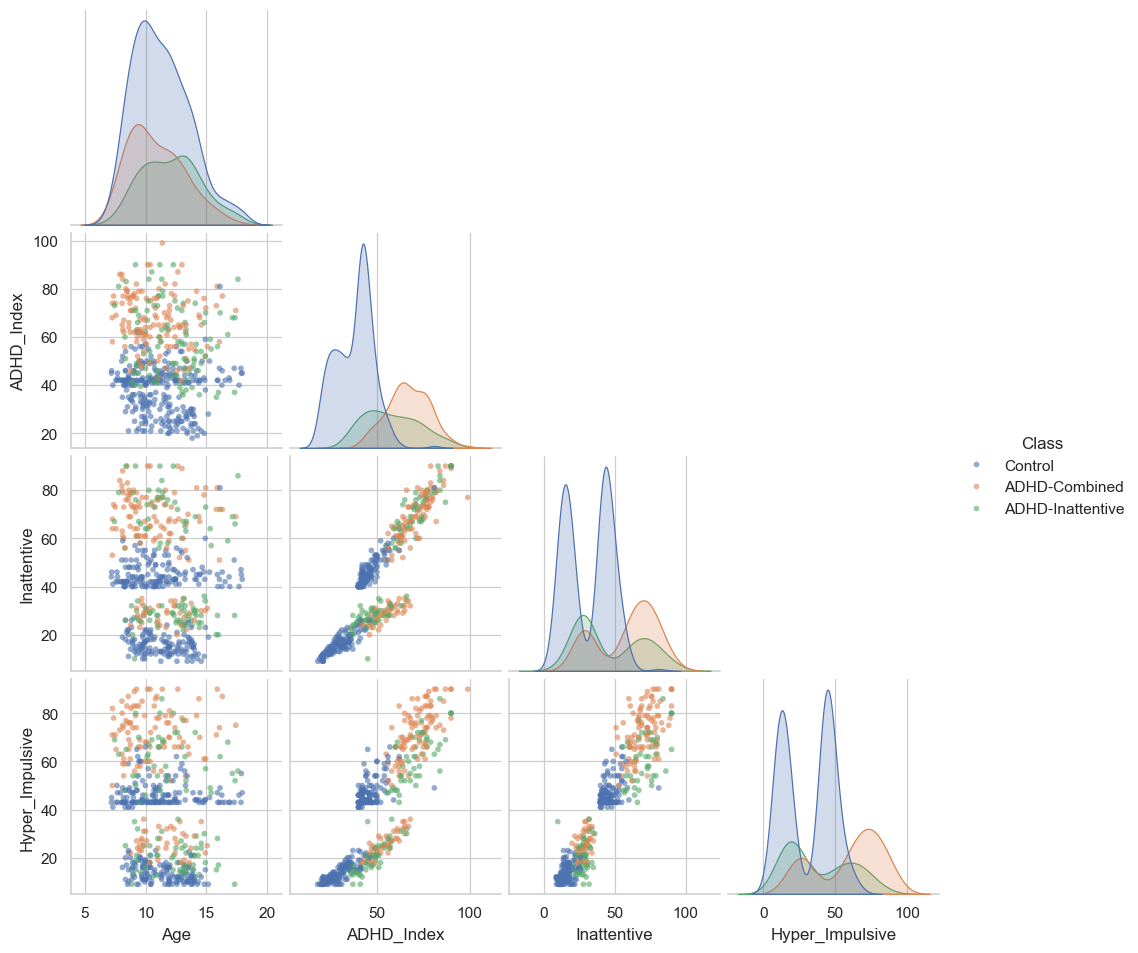

In [19]:
g = sns.pairplot(df, vars=['Age', 'ADHD_Index', 'Inattentive', 'Hyper_Impulsive'], hue='Class', hue_order=CLASS_ORDER,
                 palette=PALETTE, corner=True, diag_kind='kde', plot_kws=dict(s=14, alpha=.6, linewidth=0), height=2.2)
g.figure.savefig(f'{FIG_DIR}/C7_pairplot_scales.png'); plt.show()

## C8. Site composition and instrument codes in the final data

`Site` is **not** a model feature, but the final 505 participants come from specific sites, and the rating-scale instrument (`ADHD_Measure`) differs between sites. The first plot shows where the 505 come from; the second shows the raw scale values per instrument code, because scores from different instruments are not on the same scale.

Class,Control,ADHD-Combined,ADHD-Inattentive,Total
Site,,,,
KKI,58,17,5,80
NYU,87,76,41,204
Peking,126,37,58,221
All sites,271,130,104,505


ADHD_Measure code      IQ_Measure code          
                       1    2               1    2    3
Site                                                   
KKI                    0   80              80    0    0
NYU                    0  204               0  204    0
Peking               221    0               0    0  221

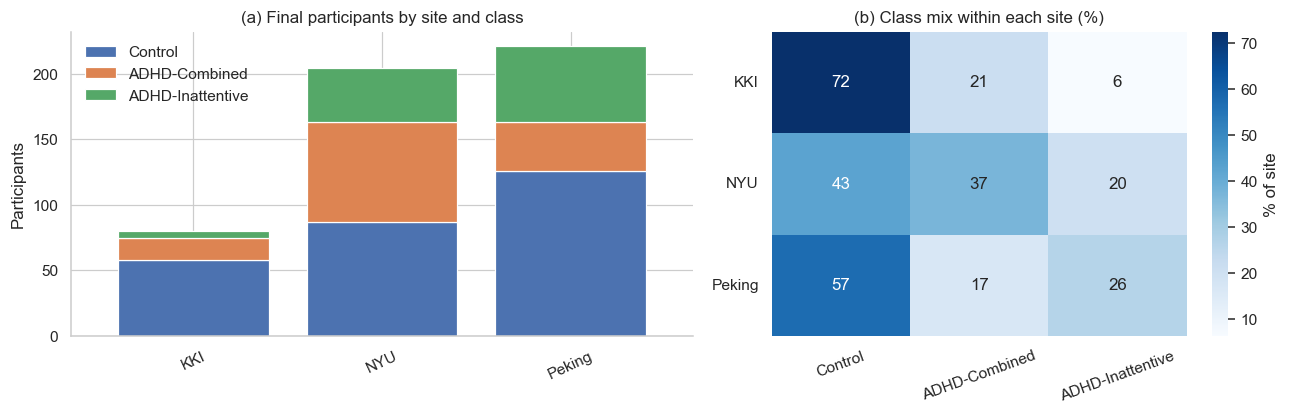

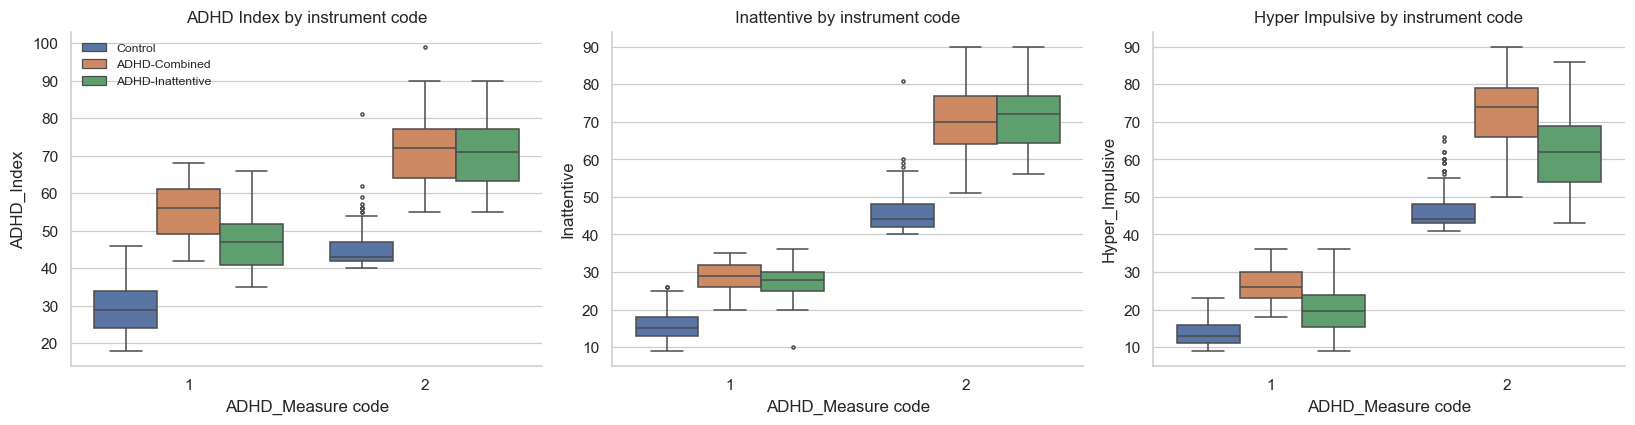

In [20]:
sc = pd.crosstab(df['Site'], df['Class']).reindex(columns=CLASS_ORDER, fill_value=0)
sc['Total'] = sc.sum(axis=1); sc.loc['All sites'] = sc.sum()
save_tab(sc, 'C8_site_by_class_final'); display(sc)

mi = pd.crosstab(df['Site'], df['ADHD_Measure']); mj = pd.crosstab(df['Site'], df['IQ_Measure'])
inst = pd.concat({'ADHD_Measure code': mi, 'IQ_Measure code': mj}, axis=1).fillna(0).astype(int)
save_tab(inst, 'C8_site_by_instrument_final'); display(inst)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={'width_ratios': [1.2, 1]})
sc.drop(index='All sites').drop(columns='Total').plot(kind='bar', stacked=True, ax=axes[0], color=[PALETTE[c] for c in CLASS_ORDER], width=.8)
axes[0].set_title('(a) Final participants by site and class'); axes[0].set_xlabel(''); axes[0].set_ylabel('Participants'); axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='', frameon=False)
share = (sc.drop(index='All sites')[CLASS_ORDER].div(sc.drop(index='All sites')['Total'], axis=0) * 100)
sns.heatmap(share, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of site'}, ax=axes[1])
axes[1].set_title('(b) Class mix within each site (%)'); axes[1].set_ylabel(''); axes[1].set_xlabel(''); axes[1].tick_params(axis='y', rotation=0); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); save_fig(fig, 'C8_site_composition_final')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['ADHD_Index', 'Inattentive', 'Hyper_Impulsive']):
    sns.boxplot(data=df, x='ADHD_Measure', y=c, hue='Class', hue_order=CLASS_ORDER, palette=PALETTE, fliersize=2, ax=ax)
    ax.set_title(c.replace('_', ' ') + ' by instrument code'); ax.set_xlabel('ADHD_Measure code')
    if ax is not axes[0]: ax.get_legend().remove()
axes[0].legend(frameon=False, fontsize=8, title='')
plt.tight_layout(); save_fig(fig, 'C8_scales_by_instrument')

## C9. Final sanity checks

In [21]:
checks = {
    'no missing values':                   df[FEATURES + ['DX']].isna().sum().sum() == 0,
    'no −999 left':                        not df[FEATURES + ['DX']].eq(-999).any().any(),
    'DX in {0,1,2}':                       set(df['DX'].unique()) == {0, 1, 2},
    'Handedness in {0,1,2}':               df['Handedness'].isin([0, 1, 2]).all(),
    'smallest class ≥ 30':                 df['DX'].value_counts().min() >= 30,
    'duplicate rows':                      int(df[FEATURES + ['DX']].duplicated().sum()),
    'Age range':                           (round(df['Age'].min(), 2), round(df['Age'].max(), 2)),
    'IQ range (V / P / Full4)':            [(int(df[c].min()), int(df[c].max())) for c in ['Verbal_IQ', 'Performance_IQ', 'Full4_IQ']],
}
for k, v in checks.items(): print(f'{k:28s}: {v}')

no missing values           : True
no −999 left                : True
DX in {0,1,2}               : True
Handedness in {0,1,2}       : True
smallest class ≥ 30         : True
duplicate rows              : 0
Age range                   : (7.17, 17.96)
IQ range (V / P / Full4)    : [(65, 158), (54, 139), (73, 153)]


# Part D — Before vs after: who was lost in the complete-case step?

The complete-case filter removed 442 of 947 labelled participants. Because missingness is structured by site, the retained and the excluded participants may differ. Only variables that are (almost) complete in the labelled set can be compared fairly: age, gender, diagnosis and site.

In [22]:
lab['retained'] = mask
lab['ClassName'] = lab['DX'].map(CLASS_NAMES)

rows = []
# class composition
ct = pd.crosstab(lab['ClassName'], lab['retained']).reindex(CLASS_ORDER)
chi2, p, *_ = stats.chi2_contingency(ct)
rows.append({'Variable': 'Diagnostic class', 'Excluded (n=%d)' % (~mask).sum(): ' / '.join(f'{ct.loc[c, False]}' for c in CLASS_ORDER),
             'Retained (n=%d)' % mask.sum(): ' / '.join(f'{ct.loc[c, True]}' for c in CLASS_ORDER), 'Test': 'chi-square', 'p': fmt_p(p)})
# gender
g = lab.dropna(subset=['Gender']); ctg = pd.crosstab(g['Gender'], g['retained']); chi2, p, *_ = stats.chi2_contingency(ctg)
rows.append({'Variable': '% male', 'Excluded (n=%d)' % (~mask).sum(): f"{g.loc[~g['retained'], 'Gender'].mean() * 100:.1f}",
             'Retained (n=%d)' % mask.sum(): f"{g.loc[g['retained'], 'Gender'].mean() * 100:.1f}", 'Test': 'chi-square', 'p': fmt_p(p)})
# age
a = lab.dropna(subset=['Age']); U, p = stats.mannwhitneyu(a.loc[a['retained'], 'Age'], a.loc[~a['retained'], 'Age'])
rows.append({'Variable': 'Age, mean (SD)', 'Excluded (n=%d)' % (~mask).sum(): f"{a.loc[~a['retained'], 'Age'].mean():.1f} ({a.loc[~a['retained'], 'Age'].std():.1f})",
             'Retained (n=%d)' % mask.sum(): f"{a.loc[a['retained'], 'Age'].mean():.1f} ({a.loc[a['retained'], 'Age'].std():.1f})", 'Test': 'Mann-Whitney', 'p': fmt_p(p)})
# site
cts = pd.crosstab(lab['Site'], lab['retained']); chi2, p, *_ = stats.chi2_contingency(cts)
rows.append({'Variable': 'Site', 'Excluded (n=%d)' % (~mask).sum(): '—', 'Retained (n=%d)' % mask.sum(): '—', 'Test': 'chi-square', 'p': fmt_p(p)})
cmp_tab = pd.DataFrame(rows); save_tab(cmp_tab, 'D1_retained_vs_excluded', index=False); display(cmp_tab)

ret = (pd.DataFrame({'labelled': lab['SiteName'].value_counts(), 'retained': lab.loc[mask, 'SiteName'].value_counts()})
         .reindex([SITE_NAMES[i] for i in range(1, 9)]).fillna(0).astype(int))
ret['retention_%'] = (ret['retained'] / ret['labelled'] * 100).round(1)
save_tab(ret, 'D2_retention_by_site'); display(ret)

,Variable,Excluded (n=442),Retained (n=505),Test,p
0,Diagnostic class,314 / 95 / 33,271 / 130 / 104,chi-square,<0.001
1,% male,57.8,66.3,chi-square,0.009
2,"Age, mean (SD)",12.7 (4.1),11.4 (2.3),Mann-Whitney,<0.001
3,Site,—,—,chi-square,<0.001


,labelled,retained,retention_%
SiteName,,,
Peking,245,221,90.2
Brown,0,0,NaN
KKI,94,80,85.1
NeuroIMAGE,73,0,0.0
NYU,263,204,77.6
OHSU,113,0,0.0
Pittsburgh,98,0,0.0
WashU,61,0,0.0


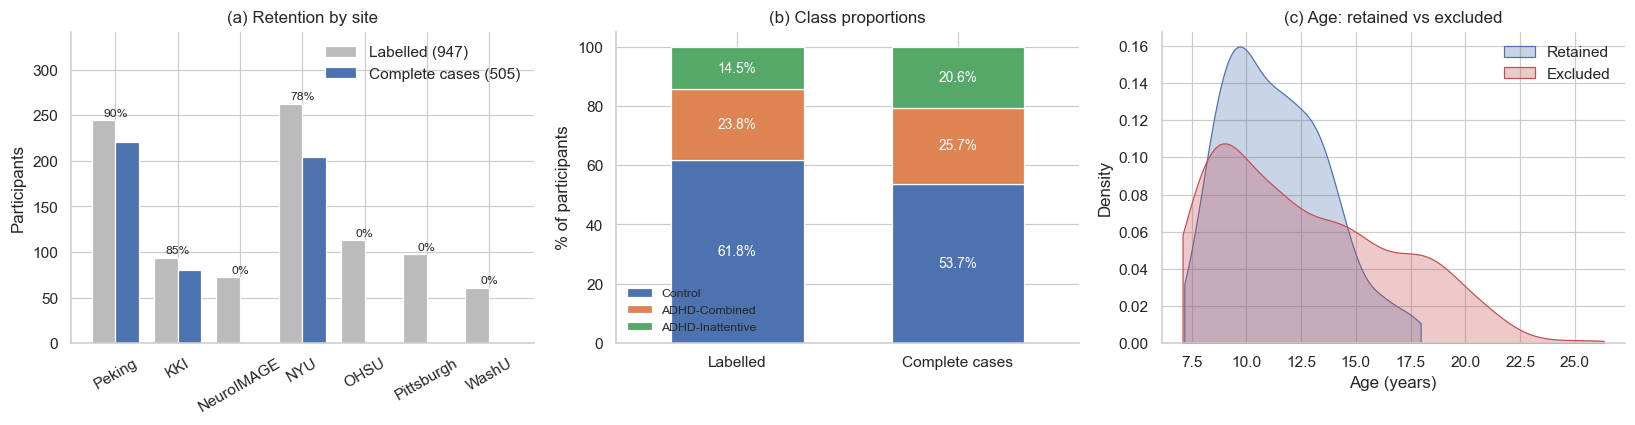

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
r = ret.dropna(subset=['labelled']); r = r[r['labelled'] > 0]
x = np.arange(len(r)); w = .38
axes[0].bar(x - w / 2, r['labelled'], w, label='Labelled (947)', color='#BBBBBB')
axes[0].bar(x + w / 2, r['retained'], w, label='Complete cases (505)', color='#4C72B0')
for i, (a_, b_, pc) in enumerate(zip(r['labelled'], r['retained'], r['retention_%'])): axes[0].text(i, max(a_, b_) + 4, f'{pc:.0f}%', ha='center', fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(r.index, rotation=30); axes[0].set_ylabel('Participants'); axes[0].set_ylim(0, r['labelled'].max() * 1.3); axes[0].legend(frameon=False, loc='upper right')
axes[0].set_title('(a) Retention by site')

pc = pd.DataFrame({'Labelled': lab['ClassName'].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
                   'Complete cases': df['Class'].value_counts(normalize=True).reindex(CLASS_ORDER) * 100})
pc.T.plot(kind='bar', stacked=True, ax=axes[1], color=[PALETTE[c] for c in CLASS_ORDER], width=.6)
for i, col in enumerate(pc.columns):
    cum = 0
    for k in CLASS_ORDER:
        axes[1].text(i, cum + pc.loc[k, col] / 2, f'{pc.loc[k, col]:.1f}%', ha='center', va='center', color='white', fontsize=9); cum += pc.loc[k, col]
axes[1].set_ylabel('% of participants'); axes[1].set_title('(b) Class proportions'); axes[1].tick_params(axis='x', rotation=0); axes[1].legend(frameon=False, fontsize=8)

sns.kdeplot(lab.loc[mask, 'Age'].dropna(), ax=axes[2], color='#4C72B0', fill=True, alpha=.3, label='Retained', cut=0)
sns.kdeplot(lab.loc[~mask, 'Age'].dropna(), ax=axes[2], color='#C44E52', fill=True, alpha=.3, label='Excluded', cut=0)
axes[2].set_title('(c) Age: retained vs excluded'); axes[2].set_xlabel('Age (years)'); axes[2].legend(frameon=False)
plt.tight_layout(); save_fig(fig, 'D3_before_after_comparison')

# Part E — Check against the numbers quoted in the manuscript

Each row compares a value stated in the *Results → Dataset and class distribution* text (and Table 1) with the value computed from the data. A ✗ means the manuscript text needs updating (or the cleaning changed).

In [24]:
miss_lab = (lab[FEATURES].isna().mean() * 100).round(1)
claims = [
    ('Rows in raw file',                             973,  n_all),
    ('Unlabelled (DX = pending)',                    26,   n_all - len(lab)),
    ('Labelled participants',                        947,  len(lab)),
    ('Labelled controls',                            585,  int((lab['DX_raw'] == 0).sum())),
    ('Labelled ADHD-combined (original)',            212,  int((lab['DX_raw'] == 1).sum())),
    ('Labelled ADHD-hyperactive/impulsive',          13,   int((lab['DX_raw'] == 2).sum())),
    ('Labelled ADHD-inattentive',                    137,  int((lab['DX_raw'] == 3).sum())),
    ('Combined after merge',                         225,  int((lab['DX'] == 1).sum())),
    ('Missing % ADHD_Index (labelled)',              41.2, miss_lab['ADHD_Index']),
    ('Missing % ADHD_Measure',                       33.6, miss_lab['ADHD_Measure']),
    ('Missing % Inattentive',                        32.8, miss_lab['Inattentive']),
    ('Missing % Hyper_Impulsive',                    32.8, miss_lab['Hyper_Impulsive']),
    ('Missing % Verbal_IQ',                          31.8, miss_lab['Verbal_IQ']),
    ('Missing % Performance_IQ',                     31.8, miss_lab['Performance_IQ']),
    ('Missing % Full4_IQ',                           9.1,  miss_lab['Full4_IQ']),
    ('Missing % IQ_Measure',                         5.2,  miss_lab['IQ_Measure']),
    ('Missing % Full2_IQ (~85%)',                    85.0, round((lab['Full2_IQ'].isna().mean() * 100), 1)),
    ('Missing % Med_Status (~40%)',                  40.0, round((lab['Med_Status'].isna().mean() * 100), 1)),
    ('Complete cases',                               505,  len(df)),
    ('Participants lost',                            442,  len(lab) - len(df)),
    ('% lost',                                       47,   round((len(lab) - len(df)) / len(lab) * 100)),
    ('Final controls',                               271,  int((df['DX'] == 0).sum())),
    ('Final ADHD-combined',                          130,  int((df['DX'] == 1).sum())),
    ('Final ADHD-inattentive',                       104,  int((df['DX'] == 2).sum())),
    ('Controls per inattentive (≈2.6)',              2.6,  round((df['DX'] == 0).sum() / (df['DX'] == 2).sum(), 1)),
    ('Training set',                                 378,  len(y_tr)),
    ('Test set',                                     127,  len(y_te)),
    ('Train: controls / combined / inattentive',     '203/97/78', '/'.join(map(str, y_tr.value_counts().sort_index().values))),
    ('Test: controls / combined / inattentive',      '68/33/26',  '/'.join(map(str, y_te.value_counts().sort_index().values))),
]
chk = pd.DataFrame(claims, columns=['Statement in manuscript', 'Manuscript', 'Computed'])
def ok(r):
    a, b = r['Manuscript'], r['Computed']
    if isinstance(a, str): return '✓' if a == b else '✗'
    tol = 1.0 if 'Full2' in r['Statement in manuscript'] or 'Med_Status' in r['Statement in manuscript'] else 0.051
    return '✓' if abs(a - b) <= tol else '✗'
chk['Match'] = chk.apply(ok, axis=1)
save_tab(chk, 'E1_manuscript_number_check', index=False)
print(f"{(chk['Match'] == '✓').sum()} / {len(chk)} statements match")
chk

28 / 29 statements match


,Statement in manuscript,Manuscript,Computed,Match
0,Rows in raw file,973,973,✓
1,Unlabelled (DX = pending),26,26,✓
2,Labelled participants,947,947,✓
3,Labelled controls,585,585,✓
4,Labelled ADHD-combined (original),212,212,✓
5,Labelled ADHD-hyperactive/impulsive,13,13,✓
6,Labelled ADHD-inattentive,137,137,✓
7,Combined after merge,225,225,✓
8,Missing % ADHD_Index (labelled),41.2,41.2,✓
9,Missing % ADHD_Measure,33.6,33.6,✓


In [25]:
print('Saved figures:'); [print('  ', f) for f in sorted(os.listdir(FIG_DIR))]
print('Saved tables :'); [print('  ', f) for f in sorted(os.listdir(TAB_DIR))]

Saved figures:
   A3_raw_dx_by_site.png
   A4_missingness_raw.png
   A5_handedness_raw_coding.png
   B5_participant_flow.png
   C2_class_distribution.png
   C4_numeric_by_class.png
   C4_numeric_density_by_class.png
   C5_categorical_by_class.png
   C6_correlation.png
   C7_pairplot_scales.png
   C8_scales_by_instrument.png
   C8_site_composition_final.png
   D3_before_after_comparison.png
   Fig1_class_distribution_final.png
Saved tables :
   A1_missing_tokens_raw.csv
   A3_site_by_dx_raw.csv
   A4_missing_by_column_raw.csv
   A5_handedness_codes_non_nyu.csv
   A6_raw_numeric_summary.csv
   B1_handedness_after_harmonisation.csv
   B3_complete_case_ablation.csv
   B3_med_status_missing_by_dx.csv
   B3_med_status_missing_by_site.csv
   B5_participant_flow.csv
   C1_table1_class_distribution.csv
   C3_descriptives_by_class.csv
   C6_spearman_correlation.csv
   C8_site_by_class_final.csv
   C8_site_by_instrument_final.csv
   D1_retained_vs_excluded.csv
   D2_retention_by_site.csv
   E1_ma

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]